# Engagement Intelligence
## Behavioral Pattern Discovery and Comparative Analytics

**Project extension:** Facebook Live Sellers in Thailand (UCI Machine Learning Repository)


**Purpose:** Extend the original exploratory analysis into a reproducible analytical workflow that compares clustering approaches, evaluates their quality, interprets engagement profiles, and prepares an interactive dashboard.

### Research questions
1. How do engagement metrics vary by post type and publication hour?
2. How strongly are reactions, comments, shares, and reaction categories associated?
3. Do posts form distinguishable engagement-behavior groups?
4. How do feature choices and preprocessing affect the groups discovered?
5. How do K-Means and Agglomerative Clustering compare on the same evaluation sample?
6. What practical, data-supported observations can be drawn from the resulting cluster profiles?

### Important interpretation note
Clustering is unsupervised: there are no ground-truth cluster labels in this dataset. Internal metrics such as the Silhouette Score help compare configurations, but they do not prove that a cluster is objectively correct or commercially useful. All conclusions should be based on the outputs generated by this notebook.

## 1. Setup and reproducibility

**Live Dashboard:** [Open Engagement Intelligence](https://engagement-intelligence-pzretlsxzxg3mtgzhxw9wy.streamlit.app/)

**GitHub Repository:** [View Source Code](https://github.com/Riaaa-creator/engagement-intelligence)

**Dataset:** [UCI Machine Learning Repository — Facebook Live Sellers in Thailand](https://archive.ics.uci.edu/dataset/488/facebook%2Blive%2Bsellers%2Bin%2Bthailand)

This notebook downloads the dataset at runtime from the public UCI Machine Learning Repository. No dataset file needs to be bundled with this project.

**Libraries:** pandas, NumPy, Matplotlib, Seaborn, scikit-learn. Streamlit is used in a later section to generate a standalone dashboard file.

In [28]:
%pip install matplotlib seaborn scikit-learn pandas numpy scipy streamlit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from pathlib import Path
import warnings
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
# Explicit color cycle for consistent plotting across Matplotlib/Seaborn versions.
from cycler import cycler
plt.rcParams["axes.prop_cycle"] = cycler(color=["#4472C4", "#ED7D31", "#70AD47", "#A5A5A5", "#8064A2"])
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

# Download the public dataset directly from the UCI Machine Learning Repository.
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00488/Live.csv"
df_raw = pd.read_csv(DATA_URL)
print(f"Loaded public dataset: {DATA_URL}")
print(f"Loaded dataset: {DATA_PATH}")
print(f"Original shape: {df_raw.shape}")
display(df_raw.head())

Loaded dataset: Facebook_Marketplace_data.csv
Original shape: (7050, 16)


,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


## 2. Dataset audit and data quality

We begin by checking the dataset shape, column types, missing values, exact duplicate rows, and columns that contain no usable information. We do not automatically replace missing engagement counts with zero: a missing value can mean something different from a recorded zero.

In [30]:
print("Shape:", df_raw.shape)
print("\nData types:")
display(df_raw.dtypes.rename("dtype").to_frame())

audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique_values": df_raw.nunique(dropna=True),
})
display(audit.sort_values(["missing_count", "unique_values"], ascending=[False, True]))

print("Exact duplicate rows:", int(df_raw.duplicated().sum()))
all_empty_cols = df_raw.columns[df_raw.isna().all()].tolist()
print("Entirely empty columns:", all_empty_cols)

Shape: (7050, 16)

Data types:


,dtype
status_id,int64
status_type,str
status_published,str
num_reactions,int64
num_comments,int64
num_shares,int64
num_likes,int64
num_loves,int64
num_wows,int64
num_hahas,int64


,dtype,missing_count,missing_pct,unique_values
Column1,float64,7050,100.0,0
Column2,float64,7050,100.0,0
Column3,float64,7050,100.0,0
Column4,float64,7050,100.0,0
status_type,str,0,0.0,4
num_angrys,int64,0,0.0,14
num_sads,int64,0,0.0,24
num_hahas,int64,0,0.0,42
num_wows,int64,0,0.0,65
num_loves,int64,0,0.0,229


Exact duplicate rows: 0
Entirely empty columns: ['Column1', 'Column2', 'Column3', 'Column4']


### Cleaning decisions

- Entirely empty columns are removed because they provide no analytical information.
- `status_id` is an identifier, not a behavioral measurement, so it is excluded from clustering.
- `status_published` is parsed as a datetime and used to derive hour, day of week, and month for exploratory analysis.
- Exact duplicate rows are reported first. We remove exact duplicates for the analytical dataset, while noting that this is a conservative rule; repeated posts with different IDs are not automatically duplicates.
- Missing values in required engagement features are handled explicitly. In this dataset, inspect the audit output before assuming any imputation is necessary.

In [31]:
df = df_raw.copy()
df = df.drop(columns=all_empty_cols, errors="ignore")

# Parse timestamps; invalid entries become NaT and are reported.
df["status_published"] = pd.to_datetime(
    df["status_published"], errors="coerce"
)

invalid_dates = int(df["status_published"].isna().sum())
print("Unparseable/missing timestamps:", invalid_dates)

duplicate_count = int(df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Exact duplicate rows removed:", duplicate_count)
print("Shape after dropping empty columns and exact duplicates:", df.shape)

# Derive calendar fields for EDA only.
df["hour"] = df["status_published"].dt.hour
df["day_of_week"] = df["status_published"].dt.day_name()
df["month"] = df["status_published"].dt.month

engagement_cols = [
    "num_reactions", "num_comments", "num_shares", "num_likes",
    "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"
]
engagement_cols = [c for c in engagement_cols if c in df.columns]

# Validate expected columns and numeric values.
required = ["status_type", "status_published", "num_reactions", "num_comments", "num_shares"]
missing_required = [c for c in required if c not in df.columns]
if missing_required:
    raise ValueError(f"Required columns missing from dataset: {missing_required}")

for col in engagement_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Remaining missing engagement values:")
display(df[engagement_cols].isna().sum().rename("missing_count").to_frame())

print("Negative engagement values:")
display((df[engagement_cols] < 0).sum().rename("negative_count").to_frame())

Unparseable/missing timestamps: 0
Exact duplicate rows removed: 0
Shape after dropping empty columns and exact duplicates: (7050, 12)
Remaining missing engagement values:


,missing_count
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0
num_sads,0
num_angrys,0


Negative engagement values:


,negative_count
num_reactions,0
num_comments,0
num_shares,0
num_likes,0
num_loves,0
num_wows,0
num_hahas,0
num_sads,0
num_angrys,0


### Missing values and invalid counts

Engagement counts should not be negative. If the audit identifies missing or negative values, the following cell excludes those rows from clustering rather than silently inventing values. This makes the treatment explicit and easy to justify. If the dataset changes, reconsider this choice and document any alternative imputation strategy.

In [32]:
# Keep rows with valid values for the numeric engagement features used later.
valid_engagement = df[engagement_cols].notna().all(axis=1)
nonnegative_engagement = (df[engagement_cols] >= 0).all(axis=1)
valid_rows = valid_engagement & nonnegative_engagement

excluded_rows = int((~valid_rows).sum())
df_analysis = df.loc[valid_rows].copy().reset_index(drop=True)

print("Rows excluded for missing/negative engagement counts:", excluded_rows)
print("Rows retained for analysis:", len(df_analysis))
print("Post types:", df_analysis["status_type"].value_counts().to_dict())

Rows excluded for missing/negative engagement counts: 0
Rows retained for analysis: 7050
Post types: {'photo': 4288, 'video': 2334, 'status': 365, 'link': 63}


## 3. Exploratory data analysis (EDA)

EDA describes the data before modeling. The charts below are intended to reveal distribution, variation, and relationships—not to establish causation. In particular, average engagement by publication hour can be affected by the types of posts published at different hours and by outliers.

In [33]:
display(df_analysis[engagement_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
num_reactions,7050.0,230.117163,462.625309,0.0,17.0,59.5,219.00,4710.0
num_comments,7050.0,224.356028,889.636820,0.0,0.0,4.0,23.00,20990.0
num_shares,7050.0,40.022553,131.599965,0.0,0.0,0.0,4.00,3424.0
num_likes,7050.0,215.043121,449.472357,0.0,17.0,58.0,184.75,4710.0
num_loves,7050.0,12.728652,39.972930,0.0,0.0,0.0,3.00,657.0
num_wows,7050.0,1.289362,8.719650,0.0,0.0,0.0,0.00,278.0
num_hahas,7050.0,0.696454,3.957183,0.0,0.0,0.0,0.00,157.0
num_sads,7050.0,0.243688,1.597156,0.0,0.0,0.0,0.00,51.0
num_angrys,7050.0,0.113191,0.726812,0.0,0.0,0.0,0.00,31.0


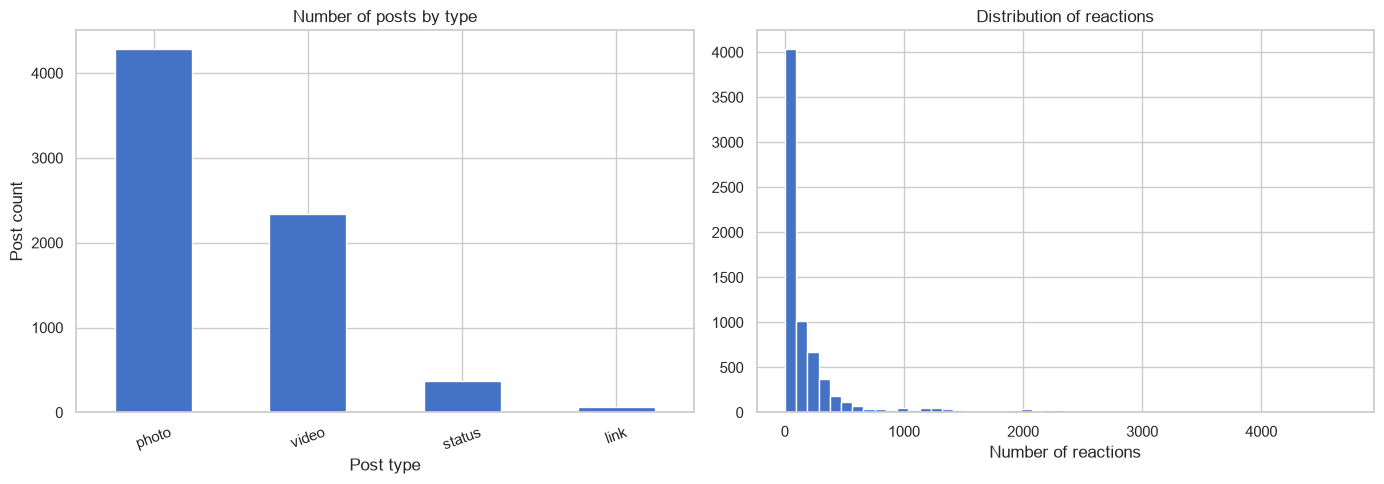

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_analysis["status_type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Number of posts by type")
axes[0].set_xlabel("Post type")
axes[0].set_ylabel("Post count")
axes[0].tick_params(axis="x", rotation=20)

axes[1].hist(df_analysis["num_reactions"], bins=50)
axes[1].set_title("Distribution of reactions")
axes[1].set_xlabel("Number of reactions")
plt.tight_layout()
plt.show()

The raw engagement distributions may be right-skewed: a small number of posts can receive far more engagement than most posts. We will inspect this rather than assume it. The clustering section tests a `log1p` transformation, which applies `log(1 + x)` and is defined for zero-valued counts.

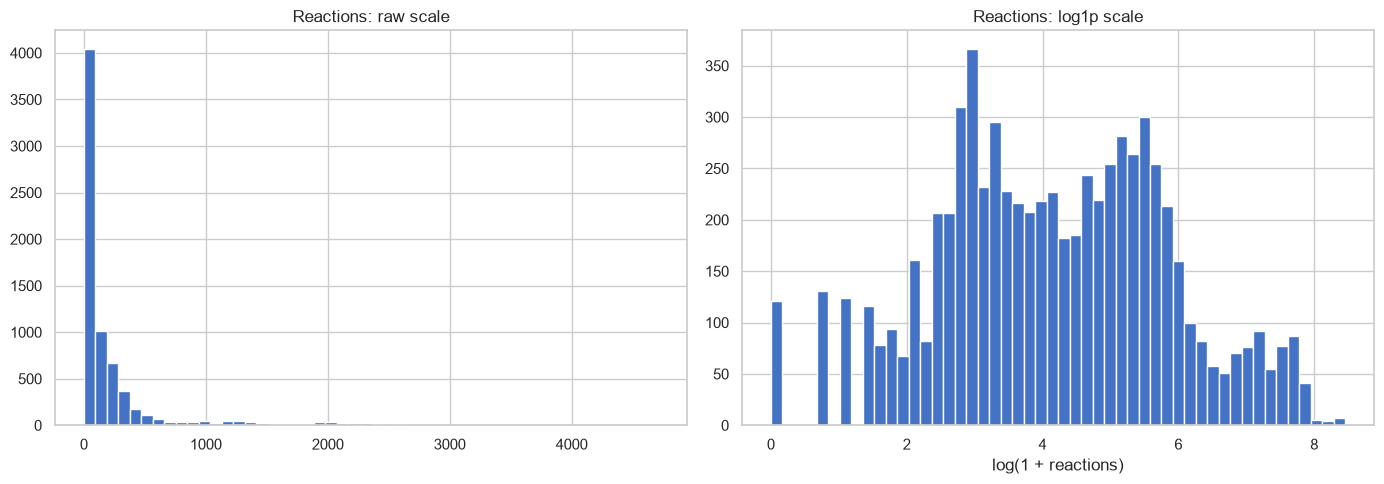

,skewness
num_hahas,20.305741
num_angrys,19.507129
num_wows,18.246813
num_sads,17.578868
num_comments,9.028850
num_shares,7.099332
num_loves,6.004845
num_likes,3.919128
num_reactions,3.738452


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(df_analysis["num_reactions"], bins=50)
axes[0].set_title("Reactions: raw scale")
axes[1].hist(np.log1p(df_analysis["num_reactions"]), bins=50)
axes[1].set_title("Reactions: log1p scale")
axes[1].set_xlabel("log(1 + reactions)")
plt.tight_layout()
plt.show()

display(df_analysis[engagement_cols].skew().sort_values(ascending=False).rename("skewness").to_frame())

### Publication time and engagement

We calculate averages and medians by hour. Medians are included because means can be pulled upward by a small number of high-engagement posts. This is descriptive analysis; it does not prove that posting at a particular hour causes more engagement.

,hour,mean_reactions,median_reactions,post_count
0,0,261.839474,79.5,380
1,1,203.315725,86.0,814
2,2,163.907618,29.0,617
3,3,290.270208,51.0,433
4,4,242.685864,49.0,382
5,5,293.870968,68.5,372
6,6,340.213198,126.5,394
7,7,183.301549,48.0,839
8,8,204.796897,36.0,709
9,9,205.780761,64.0,447


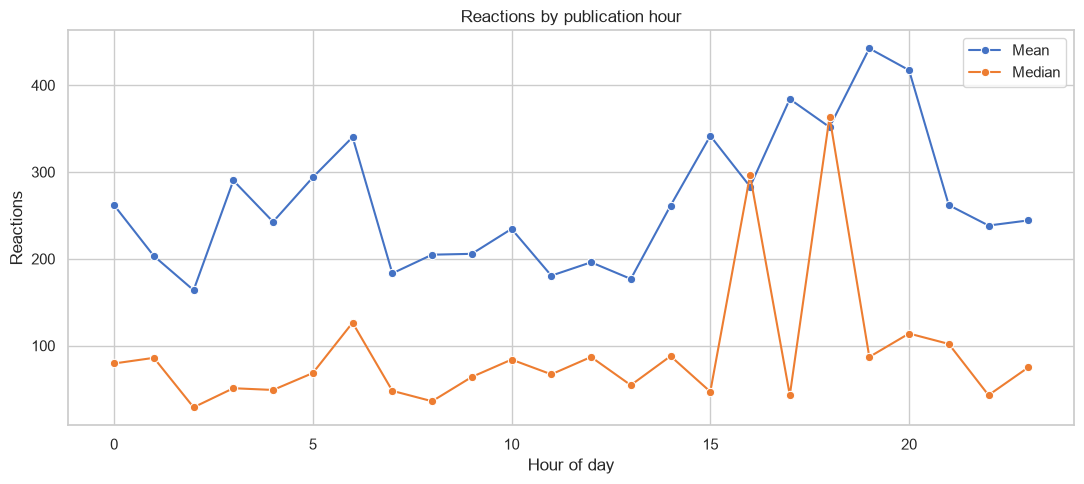

In [36]:
hourly = (
    df_analysis.dropna(subset=["hour"])
    .groupby("hour")["num_reactions"]
    .agg(mean_reactions="mean", median_reactions="median", post_count="count")
    .reset_index()
)
display(hourly)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=hourly, x="hour", y="mean_reactions", marker="o", label="Mean", ax=ax)
sns.lineplot(data=hourly, x="hour", y="median_reactions", marker="o", label="Median", ax=ax)
ax.set_title("Reactions by publication hour")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Reactions")
plt.tight_layout()
plt.show()

### Correlation between engagement metrics

Correlation captures linear association, not causation. Because `num_reactions` may overlap with its component reaction counts, high correlations between these variables are not surprising and are one reason to compare alternative feature sets.

,num_reactions,num_comments,num_shares
num_reactions,1.000000,0.150843,0.250723
num_comments,0.150843,1.000000,0.640637
num_shares,0.250723,0.640637,1.000000


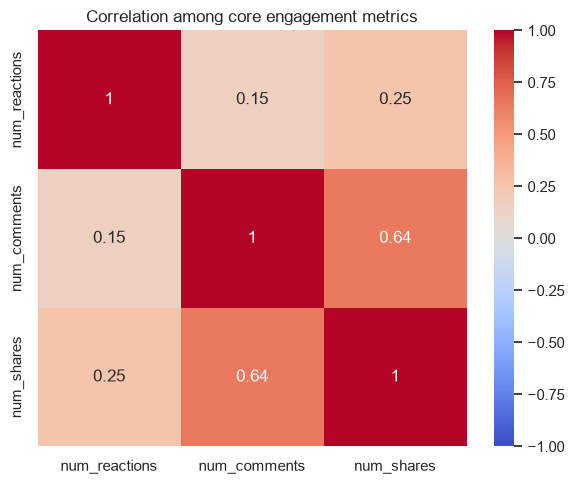

In [37]:
core_metrics = [c for c in ["num_reactions", "num_comments", "num_shares"] if c in df_analysis.columns]
corr = df_analysis[core_metrics].corr()
display(corr)

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation among core engagement metrics")
plt.tight_layout()
plt.show()

### Average engagement by post type

This comparison includes both means and medians to make the influence of extreme posts easier to see. Do not interpret a larger average as proof that a post type is always better; the sample sizes and spread also matter.

num_reactions              num_comments               num_shares             
                     mean median count         mean median count        mean median count
status_type                                                                              
link           370.142857   50.0    63     5.698413    1.0    63    4.396825    0.0    63
photo          181.290345   34.0  4288    15.993470    2.0  4288    2.553871    0.0  4288
status         438.783562  120.0   365    36.238356   10.0   365    2.558904    0.0   365
video          283.409597  160.0  2334   642.478149   39.0  2334  115.679949   12.0  2334

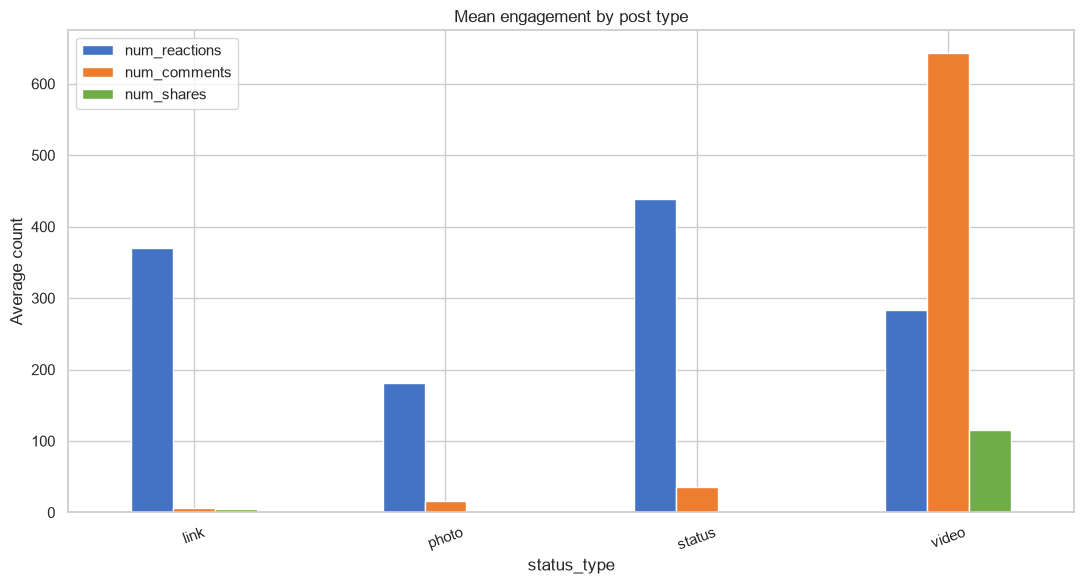

In [38]:
post_type_summary = (
    df_analysis.groupby("status_type")[["num_reactions", "num_comments", "num_shares"]]
    .agg(["mean", "median", "count"])
)
display(post_type_summary)

mean_by_type = df_analysis.groupby("status_type")[["num_reactions", "num_comments", "num_shares"]].mean()
mean_by_type.plot(kind="bar", figsize=(11, 6))
plt.title("Mean engagement by post type")
plt.ylabel("Average count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 4. Feature engineering and selection rationale

Clustering depends heavily on which variables are supplied. We will compare two feature sets:

**Feature set A — Core engagement:** reactions, comments, and shares. This is compact and focuses on the three main engagement outcomes.

**Feature set B — Detailed engagement:** comments, shares, and individual reaction categories (`likes`, `loves`, `wows`, `hahas`, `sads`, `angrys`). This emphasizes the composition of engagement. It excludes `num_reactions` because total reactions overlaps with individual reaction counts and could otherwise give the reaction dimension extra weight.

A third sensitivity analysis will add post type using one-hot encoding. We do not use integer label encoding for post type because it imposes an artificial numeric order on categories.

All count features are transformed with `log1p` and standardized. This gives each transformed numerical feature comparable scale while reducing, though not eliminating, the influence of very large counts. The feature sets are alternatives for experimentation; no feature set is guaranteed to be best in advance.

In [39]:
CORE_FEATURES = ["num_reactions", "num_comments", "num_shares"]
DETAILED_FEATURES = [
    "num_comments", "num_shares", "num_likes", "num_loves",
    "num_wows", "num_hahas", "num_sads", "num_angrys"
]
CORE_FEATURES = [c for c in CORE_FEATURES if c in df_analysis.columns]
DETAILED_FEATURES = [c for c in DETAILED_FEATURES if c in df_analysis.columns]

feature_sets = {
    "core_engagement": CORE_FEATURES,
    "detailed_reaction_mix": DETAILED_FEATURES,
}
print("Feature sets:")
for name, cols in feature_sets.items():
    print(f"- {name}: {cols}")

Feature sets:
- core_engagement: ['num_reactions', 'num_comments', 'num_shares']
- detailed_reaction_mix: ['num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows', 'num_hahas', 'num_sads', 'num_angrys']


### Prepare comparable model inputs

The transformation is fitted to the data being clustered. For the algorithm comparison below, we use the same rows and feature representation for both models. Agglomerative clustering can become expensive as dataset size grows, so the comparison is performed on a reproducible sample; the final K-Means model can then be fitted to all eligible rows.

In [40]:
def make_scaled_features(data, columns, log_transform=True):
    """Return a standardized numeric matrix and its fitted preprocessing objects."""
    values = data[columns].astype(float).copy()
    if log_transform:
        values = np.log1p(values)
    scaler = StandardScaler()
    transformed = scaler.fit_transform(values)
    return transformed, scaler

prepared = {}
for name, cols in feature_sets.items():
    X, scaler = make_scaled_features(df_analysis, cols, log_transform=True)
    prepared[name] = {"X": X, "scaler": scaler, "columns": cols}
    print(name, "matrix shape:", X.shape)

core_engagement matrix shape: (7050, 3)
detailed_reaction_mix matrix shape: (7050, 8)


## 5. Experiment 1 — Number of clusters and K-Means

The Elbow Method plots within-cluster sum of squares (inertia) for different values of `k`. Inertia always decreases as more clusters are added, so we look for a bend where improvements begin to diminish rather than choosing the lowest value automatically.

We also calculate the Silhouette Score. It ranges from -1 to 1; larger values generally indicate that observations are closer to their own cluster than to other clusters. Silhouette values can favor compact/simple structures and should be considered alongside cluster sizes and interpretability.

In [41]:
def evaluate_kmeans_range(X, k_values=range(2, 9), random_state=RANDOM_STATE):
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, random_state=random_state, n_init=10)
        labels = model.fit_predict(X)
        sil = silhouette_score(X, labels, sample_size=min(2000, len(X)), random_state=random_state)
        rows.append({
            "algorithm": "K-Means",
            "k": k,
            "inertia": model.inertia_,
            "silhouette": sil,
            "smallest_cluster": int(pd.Series(labels).value_counts().min()),
            "largest_cluster": int(pd.Series(labels).value_counts().max()),
        })
    return pd.DataFrame(rows)

kmeans_experiments = {}
for feature_name, item in prepared.items():
    results = evaluate_kmeans_range(item["X"])
    kmeans_experiments[feature_name] = results
    print(f"Results for {feature_name}")
    display(results.round(4))

Results for core_engagement


,algorithm,k,inertia,silhouette,smallest_cluster,largest_cluster
0,K-Means,2,9028.8710,0.5537,1585,5465
1,K-Means,3,4879.3721,0.4682,1176,3533
2,K-Means,4,3855.4702,0.3728,1150,2519
3,K-Means,5,3276.2457,0.3703,904,2419
4,K-Means,6,2886.3778,0.3568,587,2327
5,K-Means,7,2579.7874,0.3472,385,2358
6,K-Means,8,2290.7161,0.3287,367,1723


Results for detailed_reaction_mix


,algorithm,k,inertia,silhouette,smallest_cluster,largest_cluster
0,K-Means,2,32484.9922,0.5703,1267,5783
1,K-Means,3,26685.0772,0.3616,1015,3860
2,K-Means,4,22340.5464,0.3674,278,3782
3,K-Means,5,19956.6065,0.3479,280,3468
4,K-Means,6,17599.5445,0.3529,108,3455
5,K-Means,7,15901.3295,0.3614,99,3432
6,K-Means,8,14751.3485,0.3639,93,3442


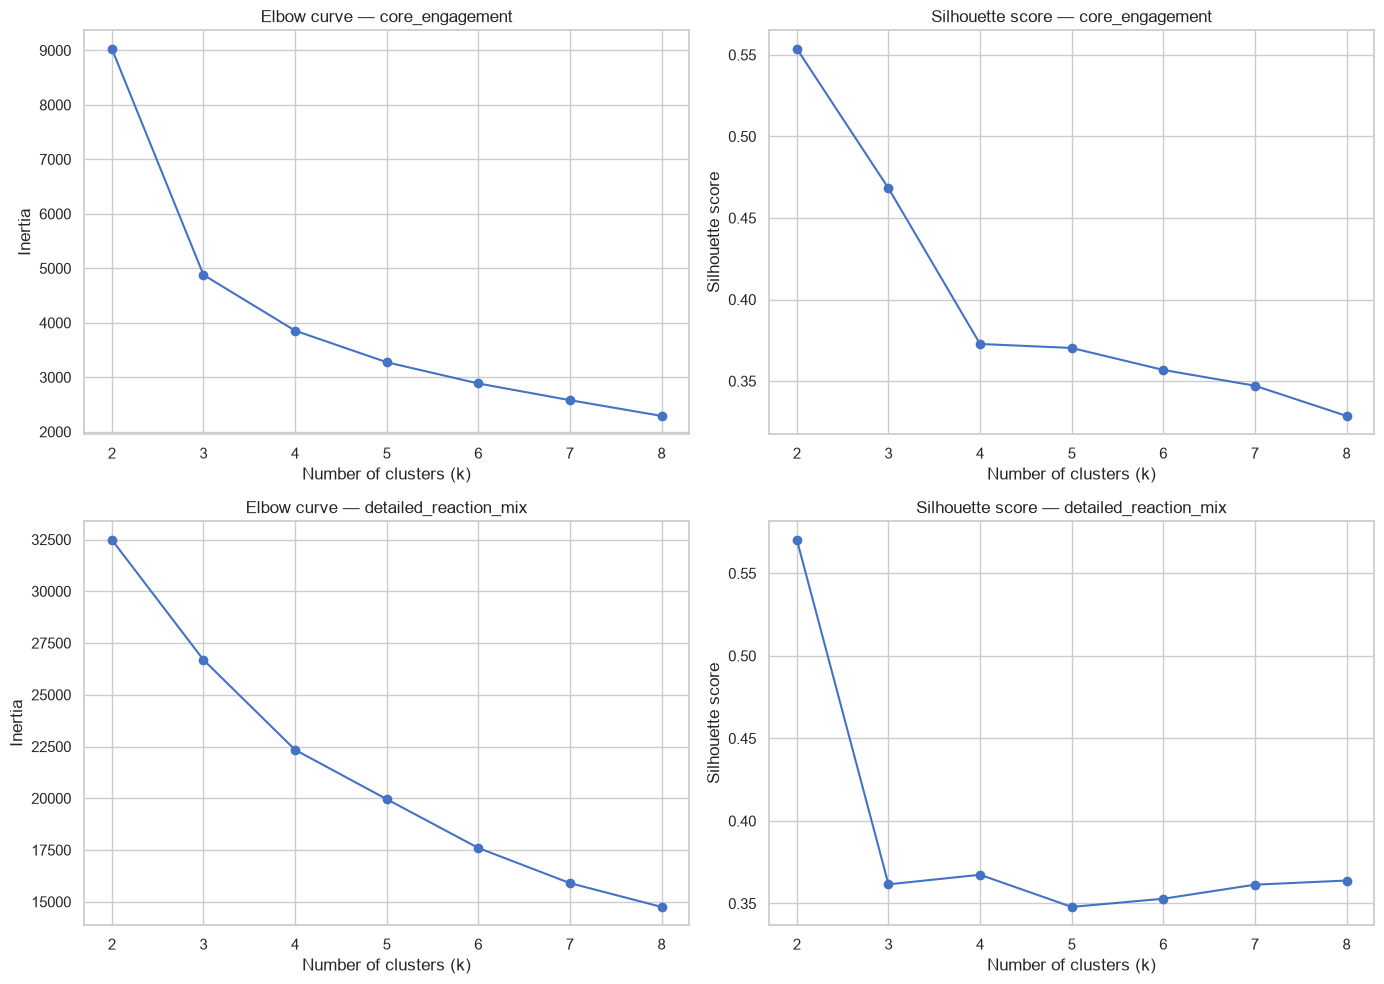

In [42]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for row, (feature_name, results) in enumerate(kmeans_experiments.items()):
    axes[row, 0].plot(results["k"], results["inertia"], marker="o")
    axes[row, 0].set_title(f"Elbow curve — {feature_name}")
    axes[row, 0].set_xlabel("Number of clusters (k)")
    axes[row, 0].set_ylabel("Inertia")

    axes[row, 1].plot(results["k"], results["silhouette"], marker="o")
    axes[row, 1].set_title(f"Silhouette score — {feature_name}")
    axes[row, 1].set_xlabel("Number of clusters (k)")
    axes[row, 1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

### Choosing a candidate `k`

Use the table and curves above to select a candidate value for each feature set. The code below proposes the `k` with the highest Silhouette Score, but this is a starting point, not an automatic final decision. Inspect whether the selected solution produces tiny clusters or profiles that are difficult to explain. The final report should explain any decision to prefer a slightly lower score for better interpretability.

In [43]:
candidate_k = {}
for feature_name, results in kmeans_experiments.items():
    best_row = results.loc[results["silhouette"].idxmax()]
    candidate_k[feature_name] = int(best_row["k"])
    print(
        f"{feature_name}: highest tested silhouette at k={int(best_row['k'])} "
        f"(score={best_row['silhouette']:.4f})"
    )

core_engagement: highest tested silhouette at k=2 (score=0.5537)
detailed_reaction_mix: highest tested silhouette at k=2 (score=0.5703)


## 6. Experiment 2 — K-Means versus Agglomerative Clustering

K-Means partitions observations around centroids and is sensitive to feature scale and outliers. Agglomerative Clustering builds a hierarchy by repeatedly merging nearby observations; Ward linkage minimizes increases in within-cluster variance and is appropriate for Euclidean numerical feature spaces.

To keep runtime and memory reasonable, this comparison uses a fixed random sample of up to 2,500 rows. Both algorithms receive the same transformed features and sample. Silhouette scores are computed on that same sample. This makes the comparison more fair than comparing scores from different rows.

In [44]:
COMPARISON_SAMPLE_SIZE = min(2500, len(df_analysis))
comparison_indices = (
    df_analysis.sample(n=COMPARISON_SAMPLE_SIZE, random_state=RANDOM_STATE).index
)
comparison_df = df_analysis.loc[comparison_indices].copy()

def prepare_sample_matrix(data, columns):
    vals = np.log1p(data[columns].astype(float))
    return StandardScaler().fit_transform(vals)

comparison_rows = []
comparison_labels = {}

for feature_name, cols in feature_sets.items():
    X_sample = prepare_sample_matrix(comparison_df, cols)
    ks = sorted(set([2, 3, 4, 5, 6, candidate_k[feature_name]]))
    for k in ks:
        # K-Means
        start = time.time()
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
        km_labels = km.fit_predict(X_sample)
        km_time = time.time() - start
        km_sil = silhouette_score(
            X_sample, km_labels,
            sample_size=min(1500, len(X_sample)),
            random_state=RANDOM_STATE
        )
        comparison_rows.append({
            "feature_set": feature_name, "algorithm": "K-Means",
            "k": k, "silhouette": km_sil, "fit_seconds": km_time,
            "smallest_cluster": int(pd.Series(km_labels).value_counts().min()),
            "largest_cluster": int(pd.Series(km_labels).value_counts().max()),
        })
        comparison_labels[(feature_name, "K-Means", k)] = km_labels

        # Agglomerative uses Ward linkage with Euclidean distance.
        start = time.time()
        agg = AgglomerativeClustering(n_clusters=k, linkage="ward")
        agg_labels = agg.fit_predict(X_sample)
        agg_time = time.time() - start
        agg_sil = silhouette_score(
            X_sample, agg_labels,
            sample_size=min(1500, len(X_sample)),
            random_state=RANDOM_STATE
        )
        comparison_rows.append({
            "feature_set": feature_name, "algorithm": "Agglomerative (Ward)",
            "k": k, "silhouette": agg_sil, "fit_seconds": agg_time,
            "smallest_cluster": int(pd.Series(agg_labels).value_counts().min()),
            "largest_cluster": int(pd.Series(agg_labels).value_counts().max()),
        })
        comparison_labels[(feature_name, "Agglomerative (Ward)", k)] = agg_labels

comparison_results = pd.DataFrame(comparison_rows).sort_values(
    ["feature_set", "k", "silhouette"], ascending=[True, True, False]
).reset_index(drop=True)
display(comparison_results.round(4))

,feature_set,algorithm,k,silhouette,fit_seconds,smallest_cluster,largest_cluster
0,core_engagement,Agglomerative (Ward),2,0.5773,0.2462,363,2137
1,core_engagement,K-Means,2,0.5563,0.1614,555,1945
2,core_engagement,K-Means,3,0.4768,0.1957,399,1282
3,core_engagement,Agglomerative (Ward),3,0.4690,0.2703,363,1537
4,core_engagement,K-Means,4,0.3690,0.2160,391,903
5,core_engagement,Agglomerative (Ward),4,0.3407,0.2465,363,773
6,core_engagement,K-Means,5,0.3746,0.3065,272,865
7,core_engagement,Agglomerative (Ward),5,0.3030,0.2514,293,764
8,core_engagement,K-Means,6,0.3595,0.2193,207,855
9,core_engagement,Agglomerative (Ward),6,0.3214,0.2469,88,676


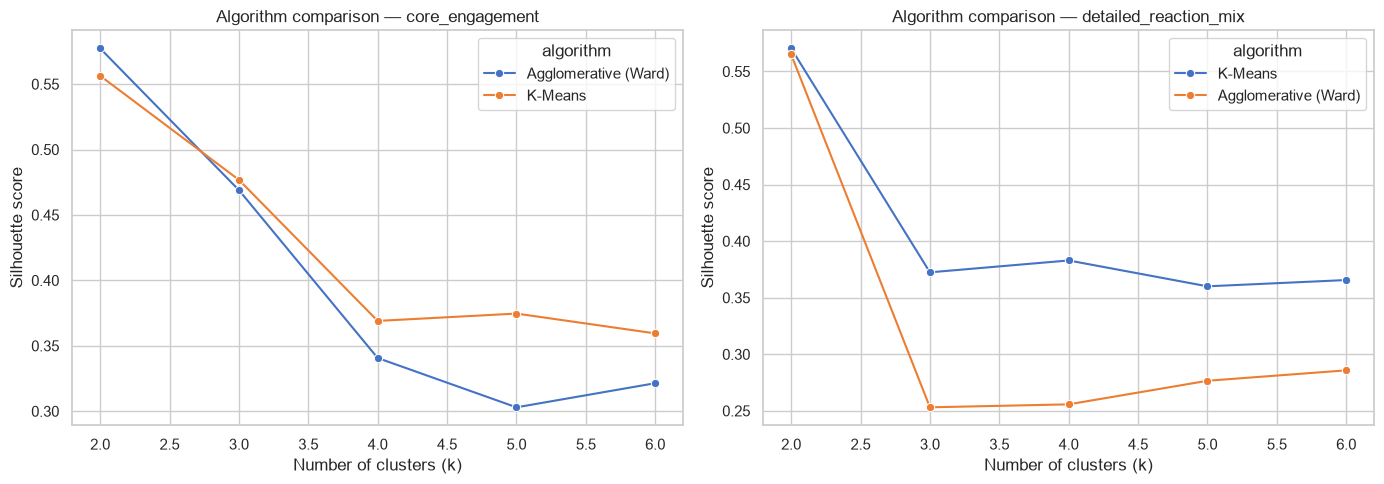

Highest silhouette configuration per feature set (interpret alongside cluster sizes):


,feature_set,algorithm,k,silhouette,fit_seconds,smallest_cluster,largest_cluster
0,core_engagement,Agglomerative (Ward),2,0.5773,0.2462,363,2137
1,detailed_reaction_mix,K-Means,2,0.5704,0.1920,446,2054


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, feature_name in zip(axes, feature_sets.keys()):
    subset = comparison_results[comparison_results["feature_set"] == feature_name]
    sns.lineplot(data=subset, x="k", y="silhouette", hue="algorithm", marker="o", ax=ax)
    ax.set_title(f"Algorithm comparison — {feature_name}")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_comparison = (
    comparison_results.sort_values("silhouette", ascending=False)
    .groupby("feature_set", as_index=False).first()
)
print("Highest silhouette configuration per feature set (interpret alongside cluster sizes):")
display(best_comparison.round(4))

### Interpretation of model comparison

Use the results rather than assuming that one algorithm must win. Compare:
- Silhouette Score (separation and cohesion),
- smallest and largest cluster sizes (possible imbalance),
- fit time (practical cost),
- whether cluster profiles are understandable and useful.

The comparison is based on a reproducible sample, so report the sample size and random seed. A small numerical difference in silhouette may not be practically meaningful.

## 7. Experiment 3 — Does including post type change the result?

The primary clustering feature sets focus on engagement. This sensitivity experiment adds `status_type` as a categorical feature using one-hot encoding. One-hot encoding avoids pretending that categories such as `photo`, `video`, and `status` have an inherent numeric order.

We keep the engagement values log-transformed and standardized. The one-hot columns are included as categorical indicators. This is a sensitivity analysis because adding post type changes what “similarity” means: posts may group partly by content format rather than engagement alone.

,algorithm,k,inertia,silhouette,smallest_cluster,largest_cluster
0,K-Means,2,9757.3180,0.5421,1563,5487
1,K-Means,3,5560.9950,0.4429,1169,3548
2,K-Means,4,4513.6647,0.3485,1141,2717
3,K-Means,5,3889.4569,0.3465,815,2441
4,K-Means,6,3497.5374,0.3281,596,2270
5,K-Means,7,3180.2203,0.3192,377,2349
6,K-Means,8,2888.1485,0.2854,380,1732


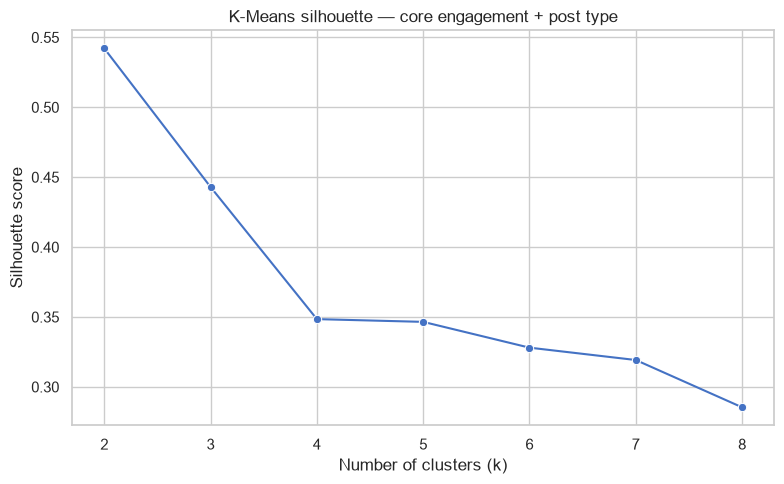

In [46]:
def make_type_aware_matrix(data, numeric_cols):
    numeric_values = np.log1p(data[numeric_cols].astype(float))
    numeric_scaled = StandardScaler().fit_transform(numeric_values)

    # Dense one-hot matrix is small for the limited number of post types.
    try:
        encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore")
    except TypeError:  # Compatibility with older scikit-learn versions
        encoder = OneHotEncoder(sparse=False, handle_unknown="ignore")
    type_matrix = encoder.fit_transform(data[["status_type"]].astype(str))

    # Weight categorical indicators less than the full numeric block so they
    # inform similarity without automatically dominating it.
    X = np.hstack([numeric_scaled, type_matrix * 0.5])
    return X, encoder

type_aware_cols = CORE_FEATURES
X_type_aware, type_encoder = make_type_aware_matrix(df_analysis, type_aware_cols)
type_sensitivity = evaluate_kmeans_range(X_type_aware, k_values=range(2, 9))
display(type_sensitivity.round(4))

fig, ax = plt.subplots(figsize=(8, 5))
sns.lineplot(data=type_sensitivity, x="k", y="silhouette", marker="o", ax=ax)
ax.set_title("K-Means silhouette — core engagement + post type")
ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

**Weighting note:** the one-hot post-type indicators are multiplied by 0.5 as an explicit experimental choice, not a universal rule. A stronger extension would test several categorical weights (for example 0.25, 0.5, and 1.0) and document how stable the solution is. The main comparison remains engagement-only so its interpretation stays clear.

## 8. Fit a final model and interpret cluster profiles

For a reproducible baseline, this section fits K-Means on all eligible rows using the core engagement features. The default `FINAL_K` is the candidate with the highest tested silhouette score for that feature set; change it if your interpretation of cluster sizes and profiles justifies another value. Do not edit the number simply to produce a preferred story.

The model uses log-transformed and standardized features. For interpretation, we attach cluster labels to the original-scale records and summarize raw engagement counts by cluster. Raw-scale summaries are easier to explain to a non-technical audience.

In [47]:
FINAL_FEATURE_SET = "core_engagement"
FINAL_K = candidate_k[FINAL_FEATURE_SET]

X_final, final_scaler = make_scaled_features(
    df_analysis, feature_sets[FINAL_FEATURE_SET], log_transform=True
)
final_kmeans = KMeans(
    n_clusters=FINAL_K, random_state=RANDOM_STATE, n_init=20
)
final_labels = final_kmeans.fit_predict(X_final)

clustered_df = df_analysis.copy()
clustered_df["cluster"] = final_labels.astype(int)

print(f"Final baseline model: K-Means, k={FINAL_K}, feature set={FINAL_FEATURE_SET}")
print("Full-data silhouette (sampled calculation if needed):",
      round(silhouette_score(
          X_final, final_labels,
          sample_size=min(2000, len(X_final)),
          random_state=RANDOM_STATE
      ), 4))
print("Cluster sizes:")
display(clustered_df["cluster"].value_counts().sort_index().rename("posts").to_frame())

Final baseline model: K-Means, k=2, feature set=core_engagement
Full-data silhouette (sampled calculation if needed): 0.5537
Cluster sizes:


,posts
cluster,
0,5465
1,1585


### Cluster profile table

Means can be strongly affected by a few highly engaged posts, so each profile includes both mean and median values. A profile should be named only after examining these numbers. Possible labels might describe high-reaction posts or discussion-heavy posts, but the names must be earned by the observed values.

In [48]:
profile_metrics = [
    c for c in [
        "num_reactions", "num_comments", "num_shares",
        "num_likes", "num_loves", "num_wows", "num_hahas", "num_sads", "num_angrys"
    ] if c in clustered_df.columns
]
cluster_profile = clustered_df.groupby("cluster")[profile_metrics].agg(["count", "mean", "median"])
display(cluster_profile.round(2))

cluster_type_mix = pd.crosstab(
    clustered_df["cluster"], clustered_df["status_type"], normalize="index"
).mul(100).round(1)
print("Post-type composition within each cluster (%):")
display(cluster_type_mix)

num_reactions                num_comments                num_shares                num_likes                num_loves         \
                count    mean median        count    mean median      count    mean median     count    mean median     count   mean   
cluster                                                                                                                                
0                5465  135.43   31.0         5465    6.20    2.0       5465    1.01    0.0      5465  133.86   31.0      5465   0.97   
1                1585  556.58  275.0         1585  976.56  424.0       1585  174.53  108.0      1585  494.97  214.0      1585  53.28   

               num_wows              num_hahas              num_sads              num_angrys               
        median    count  mean median     count  mean median    count  mean median      count  mean median  
cluster                                                                                                    
0          0.0     5465  0.34    0.0      5465  0.11    0.0     5465  0.13    0.0       5465  0.03    0.0  
1         33.0     1585  4.56    1.0      1585  2.73    1.0     1585  0.65    0.0       1585  0.38    0.0

Post-type composition within each cluster (%):


status_type,link,photo,status,video
cluster,,,,
0,1.1,72.6,5.8,20.5
1,0.3,20.1,3.2,76.4


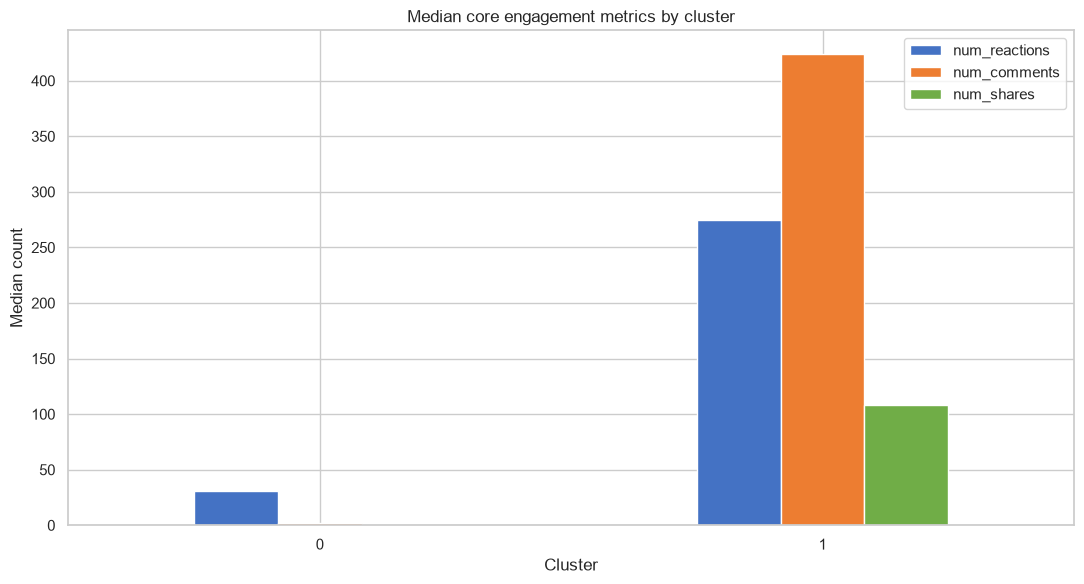

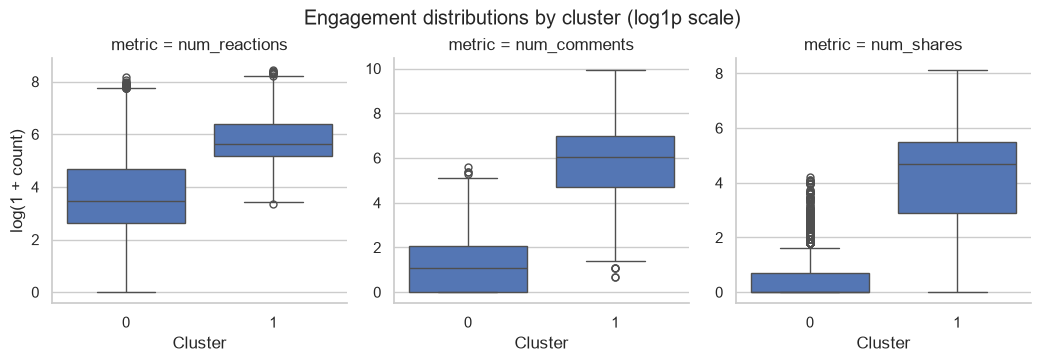

In [49]:
# Visualize median engagement by cluster. Medians reduce outlier influence.
median_profile = clustered_df.groupby("cluster")[CORE_FEATURES].median()
median_profile.plot(kind="bar", figsize=(11, 6))
plt.title("Median core engagement metrics by cluster")
plt.xlabel("Cluster")
plt.ylabel("Median count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# A log-scale boxplot can show spread while retaining zero values via log1p.
plot_data = clustered_df[["cluster"] + CORE_FEATURES].melt(
    id_vars="cluster", var_name="metric", value_name="count"
)
plot_data["log1p_count"] = np.log1p(plot_data["count"])
g = sns.catplot(
    data=plot_data, x="cluster", y="log1p_count", col="metric",
    kind="box", col_wrap=3, sharey=False, height=3.5
)
g.set_axis_labels("Cluster", "log(1 + count)")
g.fig.suptitle("Engagement distributions by cluster (log1p scale)", y=1.03)
plt.show()

### Generate cautious, data-based observations

The following code prints the largest and smallest cluster by median reactions, comments, and shares. These are descriptive observations, not causal claims. Read the profile table before turning them into recommendations.

In [50]:
for metric in CORE_FEATURES:
    medians = clustered_df.groupby("cluster")[metric].median().sort_values(ascending=False)
    print(f"\n{metric}:")
    print(f"  Highest median: cluster {int(medians.index[0])} ({medians.iloc[0]:.2f})")
    print(f"  Lowest median:  cluster {int(medians.index[-1])} ({medians.iloc[-1]:.2f})")

print("\nCluster sizes (%):")
display((clustered_df["cluster"].value_counts(normalize=True).sort_index() * 100)
        .round(2).rename("percentage").to_frame())


num_reactions:
  Highest median: cluster 1 (275.00)
  Lowest median:  cluster 0 (31.00)

num_comments:
  Highest median: cluster 1 (424.00)
  Lowest median:  cluster 0 (2.00)

num_shares:
  Highest median: cluster 1 (108.00)
  Lowest median:  cluster 0 (0.00)

Cluster sizes (%):


,percentage
cluster,
0,77.52
1,22.48


## 9. Cluster visualization using PCA

The clustering model is trained on the standardized feature space. PCA is used here only to project those features into two dimensions for visualization. It may lose information, so apparent overlap in this chart does not necessarily mean the clusters are identical in the original feature space.

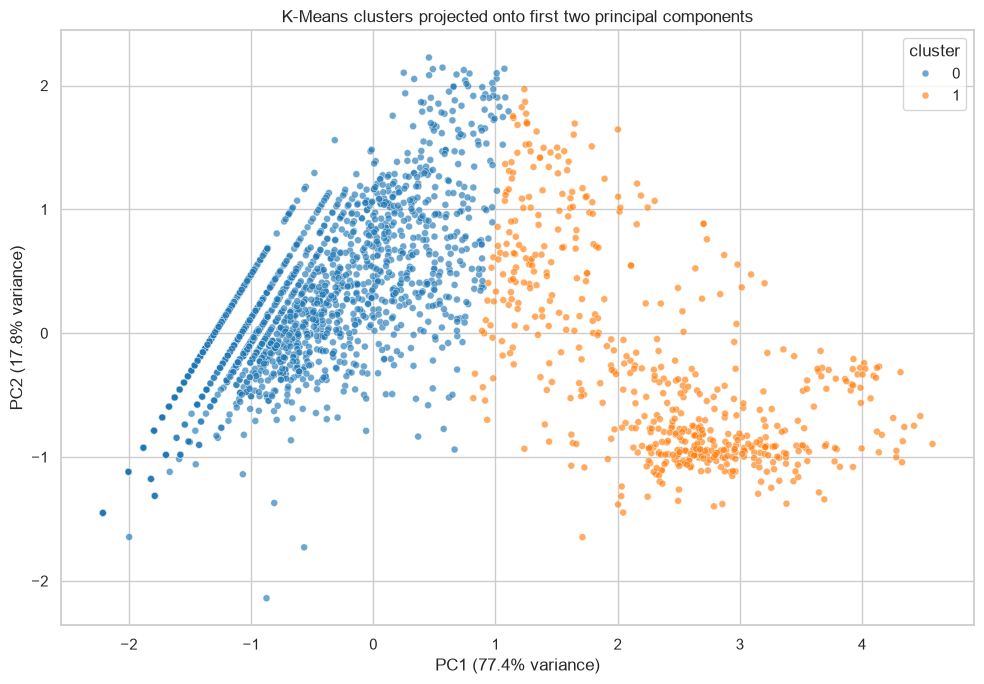

Total variance explained by first two PCs: 0.9514


In [51]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_final)
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": clustered_df["cluster"].astype(str).values
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df.sample(n=min(2500, len(pca_df)), random_state=RANDOM_STATE),
    x="PC1", y="PC2", hue="cluster", alpha=0.65, s=25, palette="tab10"
)
plt.title("K-Means clusters projected onto first two principal components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()

print("Total variance explained by first two PCs:",
      round(pca.explained_variance_ratio_.sum(), 4))

## 10. Stability and limitations

A clustering solution can change with random initialization, feature selection, scaling, and sample composition. This simple stability check repeats K-Means with different random seeds and compares the silhouette score. Similar scores do not guarantee identical labels, because cluster numbers can be permuted between runs.

In [52]:
stability_rows = []
for seed in [0, 7, 21, 42, 99]:
    model = KMeans(n_clusters=FINAL_K, random_state=seed, n_init=10)
    labels = model.fit_predict(X_final)
    score = silhouette_score(
        X_final, labels,
        sample_size=min(2000, len(X_final)),
        random_state=RANDOM_STATE
    )
    stability_rows.append({"random_state": seed, "silhouette": score, "inertia": model.inertia_})

stability_results = pd.DataFrame(stability_rows)
display(stability_results.round(4))

,random_state,silhouette,inertia
0,0,0.5537,9028.871
1,7,0.5537,9028.871
2,21,0.5537,9028.871
3,42,0.5537,9028.871
4,99,0.5537,9028.871


## 11. Export results for reuse and reporting

This section exports cleaned data with cluster assignments, model comparison results, cluster profiles, and summary metadata. These outputs can be used by the Streamlit dashboard and included in the final report.

In [53]:
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

clustered_df.to_csv(OUTPUT_DIR / "clustered_posts.csv", index=False)
comparison_results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
type_sensitivity.to_csv(OUTPUT_DIR / "post_type_sensitivity.csv", index=False)
stability_results.to_csv(OUTPUT_DIR / "kmeans_stability.csv", index=False)
cluster_type_mix.to_csv(OUTPUT_DIR / "cluster_post_type_mix_pct.csv")

# Flatten multi-index profile columns for a convenient CSV.
cluster_profile_flat = clustered_df.groupby("cluster")[profile_metrics].agg(["count", "mean", "median"])
cluster_profile_flat.columns = [f"{metric}_{stat}" for metric, stat in cluster_profile_flat.columns]
cluster_profile_flat.to_csv(OUTPUT_DIR / "cluster_profiles.csv")

metadata = {
    "project": "Engagement Intelligence",
    "dataset_file": "https://archive.ics.uci.edu/ml/machine-learning-databases/00488/Live.csv",
    "dataset_source_page": "https://archive.ics.uci.edu/dataset/488/facebook%2Blive%2Bsellers%2Bin%2Bthailand",
    "rows_original": int(len(df_raw)),
    "rows_analyzed": int(len(df_analysis)),
    "features": feature_sets,
    "final_algorithm": "K-Means",
    "final_feature_set": FINAL_FEATURE_SET,
    "final_k": int(FINAL_K),
    "random_state": RANDOM_STATE,
    "agglomerative_comparison_sample_size": int(COMPARISON_SAMPLE_SIZE),
    "notes": "Interpret cluster profiles with the report's stated limitations."
}
with open(OUTPUT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print("Exported results to:", OUTPUT_DIR.resolve())
print(sorted(p.name for p in OUTPUT_DIR.iterdir()))

Exported results to: C:\Users\Rajesh\Downloads\Engagement_Intelligence_Project_Bundle\Engagement_Intelligence\outputs
['cluster_post_type_mix_pct.csv', 'cluster_profiles.csv', 'clustered_posts.csv', 'experiment_metadata.json', 'kmeans_stability.csv', 'model_comparison.csv', 'post_type_sensitivity.csv']


## 12. Creating an interactive Streamlit dashboard

The dashboard below is written to `app.py`. Run it from a terminal in the same environment after installing Streamlit:

```bash
pip install streamlit pandas numpy matplotlib seaborn scikit-learn
streamlit run app.py
```

The dashboard uses the exported clustered dataset and experiment results. It provides a dataset overview, engagement exploration, cluster profile inspection, and model comparison. Run the export section before launching the app.

In [54]:
app_source = r'''
from pathlib import Path
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt
import seaborn as sns

st.set_page_config(page_title="Engagement Intelligence", page_icon="📊", layout="wide")
st.title("Engagement Intelligence")
st.caption("Behavioral Pattern Discovery and Comparative Analytics")

DATA_PATH = Path("outputs/clustered_posts.csv")
COMPARISON_PATH = Path("outputs/model_comparison.csv")
PROFILE_PATH = Path("outputs/cluster_profiles.csv")

if not DATA_PATH.exists():
    st.error("Missing outputs/clustered_posts.csv. Run the notebook export section first.")
    st.stop()

data = pd.read_csv(DATA_PATH)
comparison = pd.read_csv(COMPARISON_PATH) if COMPARISON_PATH.exists() else pd.DataFrame()

with st.sidebar:
    st.header("Explore")
    post_types = sorted(data["status_type"].dropna().unique().tolist())
    selected_types = st.multiselect("Post type", post_types, default=post_types)
    clusters = sorted(data["cluster"].dropna().unique().tolist())
    selected_clusters = st.multiselect("Cluster", clusters, default=clusters)
    metric_options = [c for c in ["num_reactions", "num_comments", "num_shares"] if c in data.columns]
    metric = st.selectbox("Engagement metric", metric_options, index=0)

filtered = data[
    data["status_type"].isin(selected_types) &
    data["cluster"].isin(selected_clusters)
].copy()

c1, c2, c3 = st.columns(3)
c1.metric("Posts in selection", f"{len(filtered):,}")
c2.metric("Median " + metric.replace("num_", "").replace("_", " "), f"{filtered[metric].median():,.1f}" if len(filtered) else "—")
c3.metric("Post types", f"{filtered['status_type'].nunique()}" if len(filtered) else "0")

tab1, tab2, tab3, tab4 = st.tabs(["Overview", "Engagement", "Cluster profiles", "Model comparison"])

with tab1:
    st.subheader("Dataset overview")
    st.write("The charts describe the selected records; they do not establish causal relationships.")
    left, right = st.columns(2)
    with left:
        counts = filtered["status_type"].value_counts().rename_axis("Post type").reset_index(name="Posts")
        st.bar_chart(counts.set_index("Post type"))
    with right:
        st.bar_chart(filtered["cluster"].value_counts().sort_index().rename("Posts"))
    st.dataframe(filtered.head(100), use_container_width=True)

with tab2:
    st.subheader("Engagement distribution")
    if len(filtered):
        fig, ax = plt.subplots(figsize=(9, 4))
        sns.histplot(filtered[metric].dropna(), bins=40, ax=ax)
        ax.set_title(f"Distribution of {metric}")
        st.pyplot(fig)
        st.subheader("Engagement by post type")
        summary = filtered.groupby("status_type")[metric].agg(["mean", "median", "count"]).round(2)
        st.dataframe(summary, use_container_width=True)
        st.bar_chart(summary[["mean", "median"]])
    else:
        st.info("No rows match the selected filters.")

with tab3:
    st.subheader("Cluster profiles")
    if len(filtered):
        metrics = [c for c in ["num_reactions", "num_comments", "num_shares", "num_likes", "num_loves"] if c in filtered.columns]
        profiles = filtered.groupby("cluster")[metrics].median().round(2)
        st.write("Median engagement values by cluster, after applying sidebar filters.")
        st.dataframe(profiles, use_container_width=True)
        st.bar_chart(profiles)
        mix = pd.crosstab(filtered["cluster"], filtered["status_type"], normalize="index").mul(100).round(1)
        st.write("Post-type composition within each selected cluster (%)")
        st.dataframe(mix, use_container_width=True)
    else:
        st.info("No rows match the selected filters.")

with tab4:
    st.subheader("Clustering experiment comparison")
    if not comparison.empty:
        features = sorted(comparison["feature_set"].dropna().unique().tolist())
        chosen_feature = st.selectbox("Feature set for comparison", features)
        comp = comparison[comparison["feature_set"] == chosen_feature]
        st.dataframe(comp.sort_values("silhouette", ascending=False).round(4), use_container_width=True)
        fig, ax = plt.subplots(figsize=(9, 4))
        sns.lineplot(data=comp, x="k", y="silhouette", hue="algorithm", marker="o", ax=ax)
        ax.set_ylabel("Silhouette score")
        ax.set_xlabel("Number of clusters")
        ax.set_title("Silhouette score by algorithm and cluster count")
        st.pyplot(fig)
    else:
        st.warning("Model comparison file is missing. Run the notebook experiment section and export results.")

st.download_button(
    "Download filtered records as CSV",
    data=filtered.to_csv(index=False).encode("utf-8"),
    file_name="engagement_intelligence_filtered.csv",
    mime="text/csv",
)
'''
Path("app.py").write_text(app_source, encoding="utf-8")
print("Created app.py. Run: streamlit run app.py")

Created app.py. Run: streamlit run app.py


## Conclusion

This project extended an existing exploratory analysis by introducing explicit data-quality checks, alternative feature sets, log transformation and scaling, comparative K-Means/Agglomerative experiments, quantitative evaluation, and cluster profiling. The final configuration was selected by considering internal validation scores together with cluster sizes and interpretability. The discovered profiles describe patterns in this dataset and should not be interpreted as causal effects or generalized automatically to other platforms. The Streamlit dashboard makes the analysis explorable and exports selected records for further inspection.